In [1]:
import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path
from scipy.interpolate import interp1d, CubicSpline

OUTPUT_DIR = Path("../outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
num_sensors = 32
num_samples = 600

fs = 10e6
dt = 1 / fs
c = 1500.0

source_x = 5e-3
source_y = 20e-3
pulse_width = 1.5e-6

sensor_x = np.linspace(-15e-3, 15e-3, num_sensors)
time = np.arange(num_samples) * dt

signals = np.zeros((num_sensors, num_samples))

for i in range(num_sensors):
    distance = np.sqrt(
        (source_x - sensor_x[i])**2 + source_y**2
    )
    arrival_time = distance / c

    signals[i] = np.exp(
        -0.5 * ((time - arrival_time) / pulse_width)**2
    )

x_grid = np.linspace(-10e-3, 10e-3, 100)
y_grid = np.linspace(2e-3, 30e-3, 100)
X, Y = np.meshgrid(x_grid, y_grid)

print("Signal matrix shape:", signals.shape)

Signal matrix shape: (32, 600)


In [3]:
def reconstruct_das(signal_matrix):
    image = np.zeros_like(X, dtype=float)

    for i in range(num_sensors):
        distance_map = np.sqrt(
            (X - sensor_x[i])**2 + Y**2
        )
        travel_time = distance_map / c
        indices = np.rint(travel_time / dt).astype(int)

        valid = (indices >= 0) & (indices < num_samples)
        sampled = np.zeros_like(X, dtype=float)

        sampled[valid] = signal_matrix[i, indices[valid]]
        image += sampled

    return image


def calculate_psnr(reference, estimate):
    reference = np.asarray(reference, dtype=float)
    estimate = np.asarray(estimate, dtype=float)

    if reference.shape != estimate.shape:
        raise ValueError("Image shapes must match.")

    data_range = np.max(reference) - np.min(reference)
    if data_range <= 0:
        raise ValueError("Reference image range must be positive.")

    mse = np.mean((reference - estimate) ** 2)

    if mse == 0:
        return float("inf")

    return float(10 * np.log10(data_range**2 / mse))


reference_image = reconstruct_das(signals)

print(
    "Reference self-test:",
    calculate_psnr(reference_image, reference_image)
)

Reference self-test: inf


In [5]:
dropout_patterns = {
    "Random": np.array([2, 5, 9, 12, 17, 20, 25, 29]),
    "Periodic": np.array([1, 5, 9, 13, 17, 21, 25, 29]),
    "Block": np.array([12, 13, 14, 15, 16, 17, 18, 19])
}

for name, indices in dropout_patterns.items():
    assert len(indices) == 8
    assert len(np.unique(indices)) == 8
    assert np.all((indices >= 0) & (indices < num_sensors))

print("All dropout patterns validated.")

All dropout patterns validated.


In [6]:
results = {
    "reference": "Full-array DAS image",
    "inactive_sensor_count": 8,
    "inactive_sensor_percentage": 25.0,
    "patterns": {}
}

for pattern_name, inactive_indices in dropout_patterns.items():

    active_indices = np.setdiff1d(
        np.arange(num_sensors),
        inactive_indices
    )

    damaged_signals = signals.copy()
    damaged_signals[inactive_indices, :] = 0.0

    # No interpolation
    incomplete_image = reconstruct_das(damaged_signals)

    # Linear interpolation
    linear_signals = damaged_signals.copy()

    linear_interp = interp1d(
        sensor_x[active_indices],
        signals[active_indices, :],
        axis=0,
        kind="linear",
        bounds_error=False,
        fill_value="extrapolate"
    )

    linear_signals[inactive_indices, :] = linear_interp(
        sensor_x[inactive_indices]
    )

    # Cubic spline interpolation
    spline_signals = damaged_signals.copy()

    spline_interp = CubicSpline(
        sensor_x[active_indices],
        signals[active_indices, :],
        axis=0,
        extrapolate=True
    )

    spline_signals[inactive_indices, :] = spline_interp(
        sensor_x[inactive_indices]
    )

    linear_image = reconstruct_das(linear_signals)
    spline_image = reconstruct_das(spline_signals)

    results["patterns"][pattern_name] = {
        "inactive_sensor_indices": inactive_indices.tolist(),
        "PSNR_incomplete_dB": calculate_psnr(
            reference_image, incomplete_image
        ),
        "PSNR_linear_dB": calculate_psnr(
            reference_image, linear_image
        ),
        "PSNR_spline_dB": calculate_psnr(
            reference_image, spline_image
        )
    }

    print(f"\n{pattern_name} pattern")

    for method, value in results["patterns"][pattern_name].items():
        if method.startswith("PSNR"):
            print(f"{method}: {value:.2f} dB")


Random pattern
PSNR_incomplete_dB: 21.54 dB
PSNR_linear_dB: 59.25 dB
PSNR_spline_dB: 88.17 dB

Periodic pattern
PSNR_incomplete_dB: 21.56 dB
PSNR_linear_dB: 59.40 dB
PSNR_spline_dB: 88.21 dB

Block pattern
PSNR_incomplete_dB: 20.58 dB
PSNR_linear_dB: 39.79 dB
PSNR_spline_dB: 54.79 dB


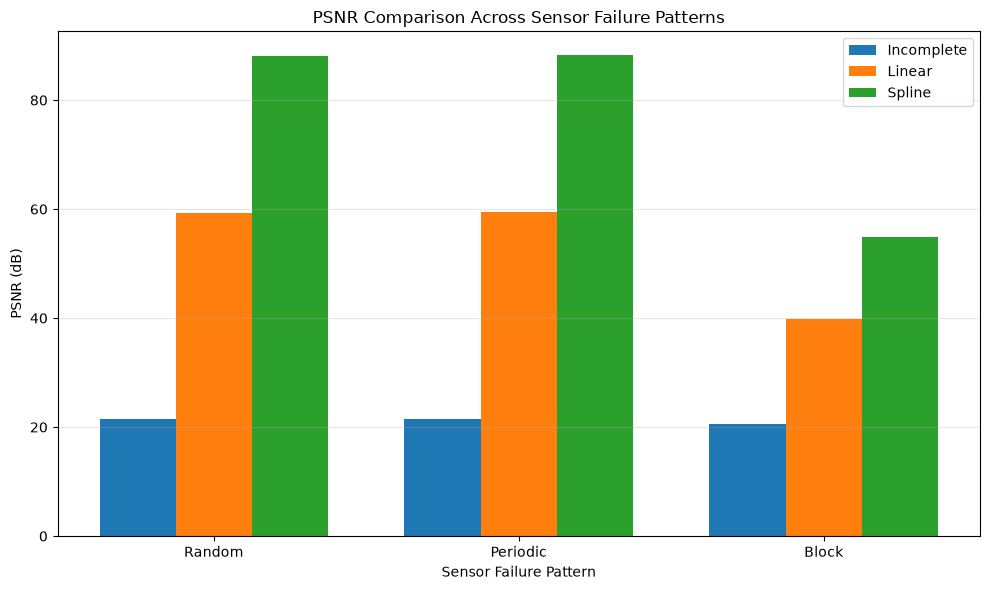

In [7]:
pattern_names = list(results["patterns"].keys())

methods = {
    "Incomplete": "PSNR_incomplete_dB",
    "Linear": "PSNR_linear_dB",
    "Spline": "PSNR_spline_dB"
}

x = np.arange(len(pattern_names))
width = 0.25

plt.figure(figsize=(10, 6))

for j, (method_name, result_key) in enumerate(methods.items()):
    values = [
        results["patterns"][pattern][result_key]
        for pattern in pattern_names
    ]

    plt.bar(
        x + (j - 1) * width,
        values,
        width,
        label=method_name
    )

plt.xlabel("Sensor Failure Pattern")
plt.ylabel("PSNR (dB)")
plt.title("PSNR Comparison Across Sensor Failure Patterns")
plt.xticks(x, pattern_names)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "../outputs/day46_psnr_failure_patterns.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
with open(
    OUTPUT_DIR / "day46_psnr_failure_patterns_results.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(results, f, indent=4, ensure_ascii=False)

print("Results saved to:", OUTPUT_DIR / "day46_psnr_failure_patterns_results.json")
print("Plot saved to: ../outputs/day46_psnr_failure_patterns.png")

Results saved to: ..\outputs\day46_psnr_failure_patterns_results.json
Plot saved to: ../outputs/day46_psnr_failure_patterns.png
